# Phase 2: Probability and Probability Distributions
**Student:** Mohammad Hossein Amini (403100065)
**Course:** Statistics and Its Applications
**Instructor:** Dr. Kasra Alishahi

## 1. Introduction
In this phase, we translate the real data into the language of probability. We focus on marginal, joint, and conditional probabilities, independence, binomial and normal distributions, and Bayes' theorem.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from math import comb

# Set plot style
sns.set_theme(style="whitegrid")

# Load Clean Data
df = pd.read_csv("../data/clean_data.csv")
print("Data loaded successfully.")

Data loaded successfully.


## 2. Define Events
We define three binary events:
- **Event A:** Smoker (SMQ020 == 1)
- **Event B:** Tooth Decay (OHQ660 == 1)
- **Event C:** High Sugar Intake (DR1TSUGR > 100)

In [10]:
# Create binary variables for events
df['Event_A_Smoker'] = (df['SMQ020'] == 1.0).astype(int)
df['Event_B_Decay'] = (df['OHQ660'] == 1.0).astype(int)
df['Event_C_HighSugar'] = (df['DR1TSUGR'] > 100).astype(int)

# Marginal Probabilities
p_smoker = df['Event_A_Smoker'].mean()
p_decay = df['Event_B_Decay'].mean()
p_high_sugar = df['Event_C_HighSugar'].mean()

print("=== Marginal Probabilities ===")
print(f"P(Smoker) = {p_smoker:.4f}")
print(f"P(Tooth Decay) = {p_decay:.4f}")
print(f"P(High Sugar > 100g) = {p_high_sugar:.4f}")

=== Marginal Probabilities ===
P(Smoker) = 0.4133
P(Tooth Decay) = 0.3718
P(High Sugar > 100g) = 0.3730


## 3. Joint and Conditional Probabilities
We calculate the probability of two events happening together, and the probability of an event given another has occurred.

In [11]:
# Joint Probabilities
p_smoker_and_decay = ((df['Event_A_Smoker'] == 1) & (df['Event_B_Decay'] == 1)).mean()
p_smoker_and_sugar = ((df['Event_A_Smoker'] == 1) & (df['Event_C_HighSugar'] == 1)).mean()
p_decay_and_sugar = ((df['Event_B_Decay'] == 1) & (df['Event_C_HighSugar'] == 1)).mean()

print("=== Joint Probabilities ===")
print(f"P(Smoker AND Decay) = {p_smoker_and_decay:.4f}")
print(f"P(Smoker AND High Sugar) = {p_smoker_and_sugar:.4f}")
print(f"P(Decay AND High Sugar) = {p_decay_and_sugar:.4f}")

# Conditional Probabilities
p_decay_given_smoker = p_smoker_and_decay / p_smoker
p_decay_given_sugar = p_decay_and_sugar / p_high_sugar
p_smoker_given_decay = p_smoker_and_decay / p_decay

print("\n=== Conditional Probabilities ===")
print(f"P(Decay | Smoker) = {p_decay_given_smoker:.4f}")
print(f"P(Decay | High Sugar) = {p_decay_given_sugar:.4f}")
print(f"P(Smoker | Decay) = {p_smoker_given_decay:.4f}")

# Independence Check
print("\n=== Independence Check ===")
expected_joint = p_smoker * p_decay
print(f"P(Smoker) * P(Decay) = {expected_joint:.4f}")
print(f"Actual P(Smoker AND Decay) = {p_smoker_and_decay:.4f}")
if abs(p_smoker_and_decay - expected_joint) < 0.01:
    print("-> Events seem independent.")
else:
    print("-> Events are likely dependent.")

=== Joint Probabilities ===
P(Smoker AND Decay) = 0.1844
P(Smoker AND High Sugar) = 0.1585
P(Decay AND High Sugar) = 0.1525

=== Conditional Probabilities ===
P(Decay | Smoker) = 0.4462
P(Decay | High Sugar) = 0.4087
P(Smoker | Decay) = 0.4961

=== Independence Check ===
P(Smoker) * P(Decay) = 0.1537
Actual P(Smoker AND Decay) = 0.1844
-> Events are likely dependent.


## 4. Binomial Distribution
We model the number of smokers in a random sample of 10 people.

=== Binomial Distribution (n=10) ===
Expected Value (Mean) = 4.13
Variance = 2.42


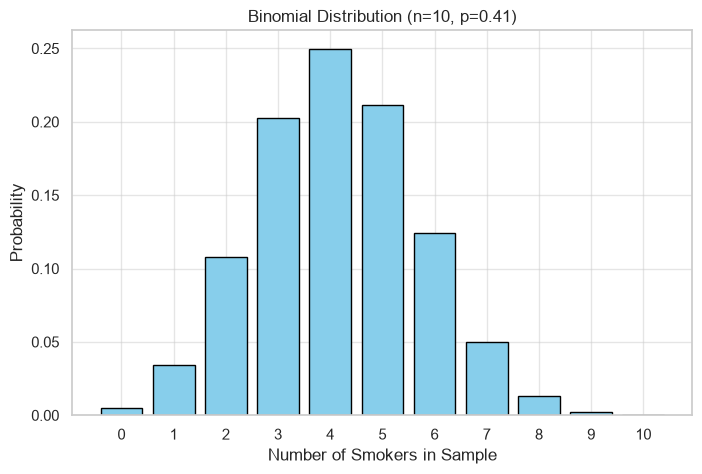

In [12]:
n = 10
p = p_smoker
x_values = np.arange(0, n + 1)

# Calculate Binomial Probabilities
binomial_probs = [comb(n, x) * (p ** x) * ((1 - p) ** (n - x)) for x in x_values]

# Expected Value and Variance
mean_binomial = n * p
var_binomial = n * p * (1 - p)

print("=== Binomial Distribution (n=10) ===")
print(f"Expected Value (Mean) = {mean_binomial:.2f}")
print(f"Variance = {var_binomial:.2f}")

# Plot
plt.figure(figsize=(8, 5))
plt.bar(x_values, binomial_probs, color='skyblue', edgecolor='black')
plt.title(f'Binomial Distribution (n=10, p={p:.2f})')
plt.xlabel('Number of Smokers in Sample')
plt.ylabel('Probability')
plt.xticks(x_values)
plt.show()

## 5. Normal Distribution Check (Sugar Intake)
We check if the continuous variable (Sugar Intake) follows a normal distribution.

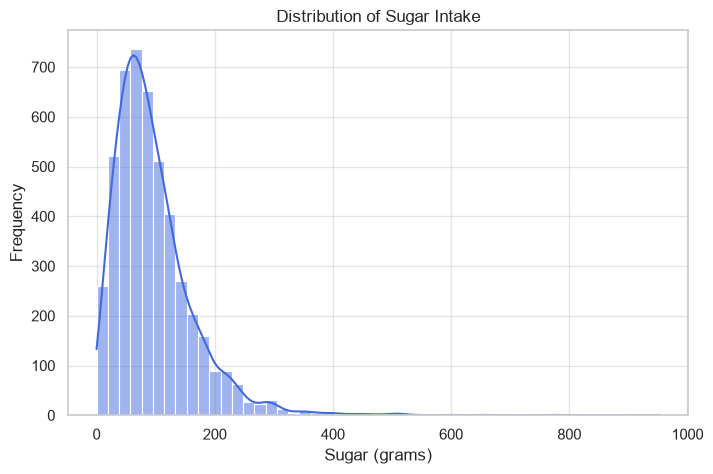

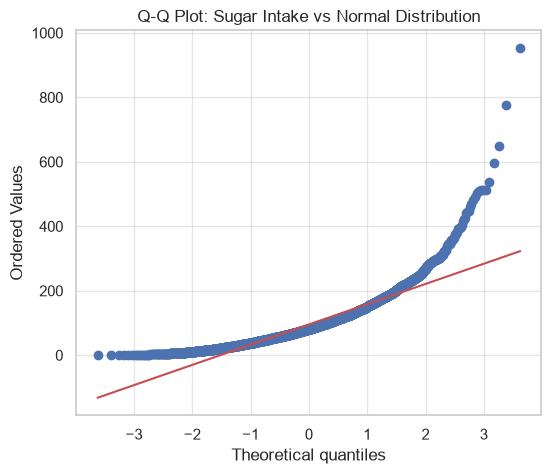

Shapiro-Wilk p-value = 1.5099e-55
-> Sugar intake is NOT normally distributed (p < 0.05).


In [13]:
sugar = df['DR1TSUGR'].dropna()

# Histogram
plt.figure(figsize=(8, 5))
sns.histplot(sugar, kde=True, color='royalblue', bins=50)
plt.title('Distribution of Sugar Intake')
plt.xlabel('Sugar (grams)')
plt.ylabel('Frequency')
plt.show()

# Q-Q Plot
plt.figure(figsize=(6, 5))
stats.probplot(sugar, dist="norm", plot=plt)
plt.title('Q-Q Plot: Sugar Intake vs Normal Distribution')
plt.show()

# Shapiro-Wilk Test
sample_sugar = sugar.sample(min(5000, len(sugar)), random_state=42)
shapiro_stat, shapiro_p = stats.shapiro(sample_sugar)
print(f"Shapiro-Wilk p-value = {shapiro_p:.4e}")
if shapiro_p < 0.05:
    print("-> Sugar intake is NOT normally distributed (p < 0.05).")
else:
    print("-> Sugar intake is approximately normally distributed.")

## 6. Expectation, Variance, and Covariance
We calculate the expected value, variance, and the relationship between Sugar Intake and Age.

=== Expectation & Variance of Sugar Intake ===
Mean = 95.47
Variance = 4641.38
Standard Deviation = 68.13

=== Covariance & Correlation (Sugar vs Age) ===
Covariance = -15.90
Correlation = -0.01


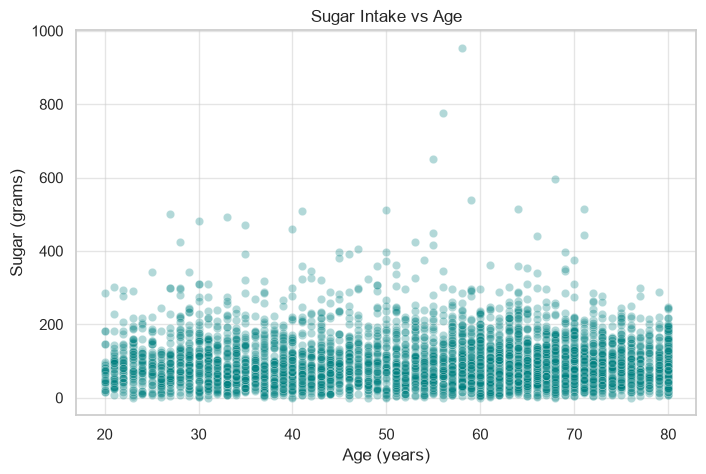

In [14]:
print("=== Expectation & Variance of Sugar Intake ===")
print(f"Mean = {sugar.mean():.2f}")
print(f"Variance = {sugar.var():.2f}")
print(f"Standard Deviation = {sugar.std():.2f}")

# Covariance and Correlation
cov_sugar_age = df['DR1TSUGR'].cov(df['RIDAGEYR'])
corr_sugar_age = df['DR1TSUGR'].corr(df['RIDAGEYR'])
print("\n=== Covariance & Correlation (Sugar vs Age) ===")
print(f"Covariance = {cov_sugar_age:.2f}")
print(f"Correlation = {corr_sugar_age:.2f}")

# Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='RIDAGEYR', y='DR1TSUGR', data=df, alpha=0.3, color='teal')
plt.title('Sugar Intake vs Age')
plt.xlabel('Age (years)')
plt.ylabel('Sugar (grams)')
plt.show()

## 7. Bayes Theorem & NHANES Specific Tasks
- Calculating P(Smoker | Decay) using Bayes' formula.
- Conditional probability by gender.
- Comparing unweighted vs. weighted probabilities.

In [19]:
# Bayes Theorem
print("=== Bayes Theorem ===")
# P(Smoker | Decay) = P(Decay | Smoker) * P(Smoker) / P(Decay)
p_smoker_given_decay_bayes = (p_decay_given_smoker * p_smoker) / p_decay
print(f"P(Smoker | Decay) computed via Bayes = {p_smoker_given_decay_bayes:.4f}")

# Conditional Probability by Gender (NHANES Task A1)
print("\n=== Conditional Probability by Gender ===")
male_df = df[df['RIAGENDR'] == 'Male']
female_df = df[df['RIAGENDR'] == 'Female']

p_decay_given_smoker_male = ((male_df['Event_A_Smoker'] == 1) & (male_df['Event_B_Decay'] == 1)).sum() / (male_df['Event_A_Smoker'] == 1).sum()
p_decay_given_smoker_female = ((female_df['Event_A_Smoker'] == 1) & (female_df['Event_B_Decay'] == 1)).sum() / (female_df['Event_A_Smoker'] == 1).sum()

print(f"P(Decay | Smoker, Male) = {p_decay_given_smoker_male:.4f}")
print(f"P(Decay | Smoker, Female) = {p_decay_given_smoker_female:.4f}")

# Unweighted vs Weighted Probability (NHANES Task A4)
print("\n=== Unweighted vs Weighted Probability ===")
unweighted_p_decay = df['Event_B_Decay'].mean()
weighted_p_decay = (df['Event_B_Decay'] * df['WTMEC2YR']).sum() / df['WTMEC2YR'].sum()

print(f"Unweighted P(Decay) = {unweighted_p_decay:.4f}")
print(f"Weighted P(Decay) = {weighted_p_decay:.4f}")
print("-> Weighted probability is a better estimate for the US population.")

=== Bayes Theorem ===
P(Smoker | Decay) computed via Bayes = 0.4961

=== Conditional Probability by Gender ===
P(Decay | Smoker, Male) = 0.4304
P(Decay | Smoker, Female) = 0.4625

=== Unweighted vs Weighted Probability ===
Unweighted P(Decay) = 0.3718
Weighted P(Decay) = 0.3465
-> Weighted probability is a better estimate for the US population.


## 8. Empirical vs Theoretical Binomial Distribution
We simulate 500 random samples of size 10 to compare the empirical distribution with the theoretical binomial distribution. We also note that the binomial assumption (constant p) is violated in our data.

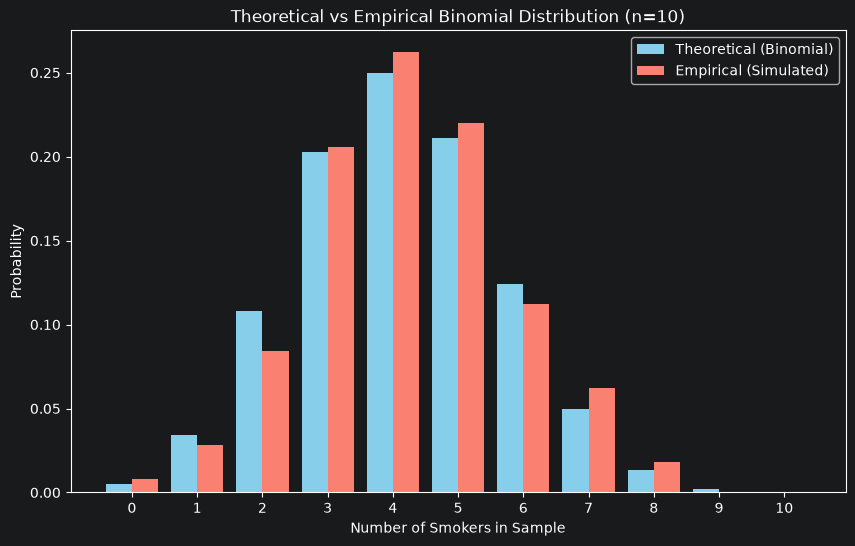

Note: The binomial model assumes a constant probability of success (p) for each trial.
However, in our data, the probability of smoking varies by gender, age, and other factors.
Therefore, the empirical distribution might not perfectly match the theoretical one.


In [20]:
sample_size = 10
num_simulations = 500
empirical_smokers = []

for _ in range(num_simulations):
    sample = df['Event_A_Smoker'].sample(n=sample_size, replace=True)
    empirical_smokers.append(sample.sum())

empirical_counts = pd.Series(empirical_smokers).value_counts(normalize=True).sort_index()
for i in range(11):
    if i not in empirical_counts:
        empirical_counts[i] = 0
empirical_counts = empirical_counts.sort_index()

plt.figure(figsize=(10, 6))
plt.bar(x_values - 0.2, binomial_probs, width=0.4, label='Theoretical (Binomial)', color='skyblue')
plt.bar(x_values + 0.2, empirical_counts.values, width=0.4, label='Empirical (Simulated)', color='salmon')
plt.title('Theoretical vs Empirical Binomial Distribution (n=10)')
plt.xlabel('Number of Smokers in Sample')
plt.ylabel('Probability')
plt.xticks(x_values)
plt.legend()
plt.show()

print("Note: The binomial model assumes a constant probability of success (p) for each trial.")
print("However, in our data, the probability of smoking varies by gender, age, and other factors.")
print("Therefore, the empirical distribution might not perfectly match the theoretical one.")